In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition
from tqdm import tqdm
from behavior_fw.io.load_dataset import load_experiment_dataset

In [2]:
from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.visualization.plot_density import (
    plot_dynamic_cartesian_densities,
    plot_dynamic_polar_densities,
)
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory

In [3]:
path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 


In [4]:
df_metadata = create_experiments_metadata(path_dir_dataset)
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,095930,2026-08-15 09:59:30,Gr43a,OptoCL,ATR
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR
...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR


In [5]:
genotype="Gr5a"
protocol="OptoCL"
medium="ATR"
condition_type = f"{genotype}_{protocol}_{medium}"
df = select_exp_condition(df_metadata, genotype=genotype, protocol=protocol, medium=medium)
df


,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
63,20260816_105347_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260816,105347,2026-08-16 10:53:47,Gr5a,OptoCL,ATR
64,20260816_125518_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260816,125518,2026-08-16 12:55:18,Gr5a,OptoCL,ATR
65,20260809_175603_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,175603,2026-08-09 17:56:03,Gr5a,OptoCL,ATR
66,20260809_182046_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,182046,2026-08-09 18:20:46,Gr5a,OptoCL,ATR
67,20260809_184634_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,184634,2026-08-09 18:46:34,Gr5a,OptoCL,ATR
69,20260809_193955_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,193955,2026-08-09 19:39:55,Gr5a,OptoCL,ATR
71,20260809_203206_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,203206,2026-08-09 20:32:06,Gr5a,OptoCL,ATR
73,20260924_164719_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260924,164719,2026-09-24 16:47:19,Gr5a,OptoCL,ATR
74,20260924_173331_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260924,173331,2026-09-24 17:33:31,Gr5a,OptoCL,ATR
75,20260925_090010_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260925,090010,2026-09-25 09:00:10,Gr5a,OptoCL,ATR


In [6]:
atr_dataset = load_experiment_dataset(df, fps=60.0)

print(f"Loaded {len(atr_dataset)} flies into memory!")
print("Columns in df_track:", atr_dataset[0]["df_track"].columns.tolist())

Error processing index 2 (20260809_175603): 'ori_angle_cal'
Error processing index 3 (20260809_182046): 'ori_angle_cal'
Error processing index 4 (20260809_184634): 'ori_angle_cal'
Error processing index 5 (20260809_193955): 'ori_angle_cal'
Error processing index 6 (20260809_203206): 'ori_angle_cal'
Loaded 41 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


3.0149359929088706 -5.121893862193295 0.38520028219800495


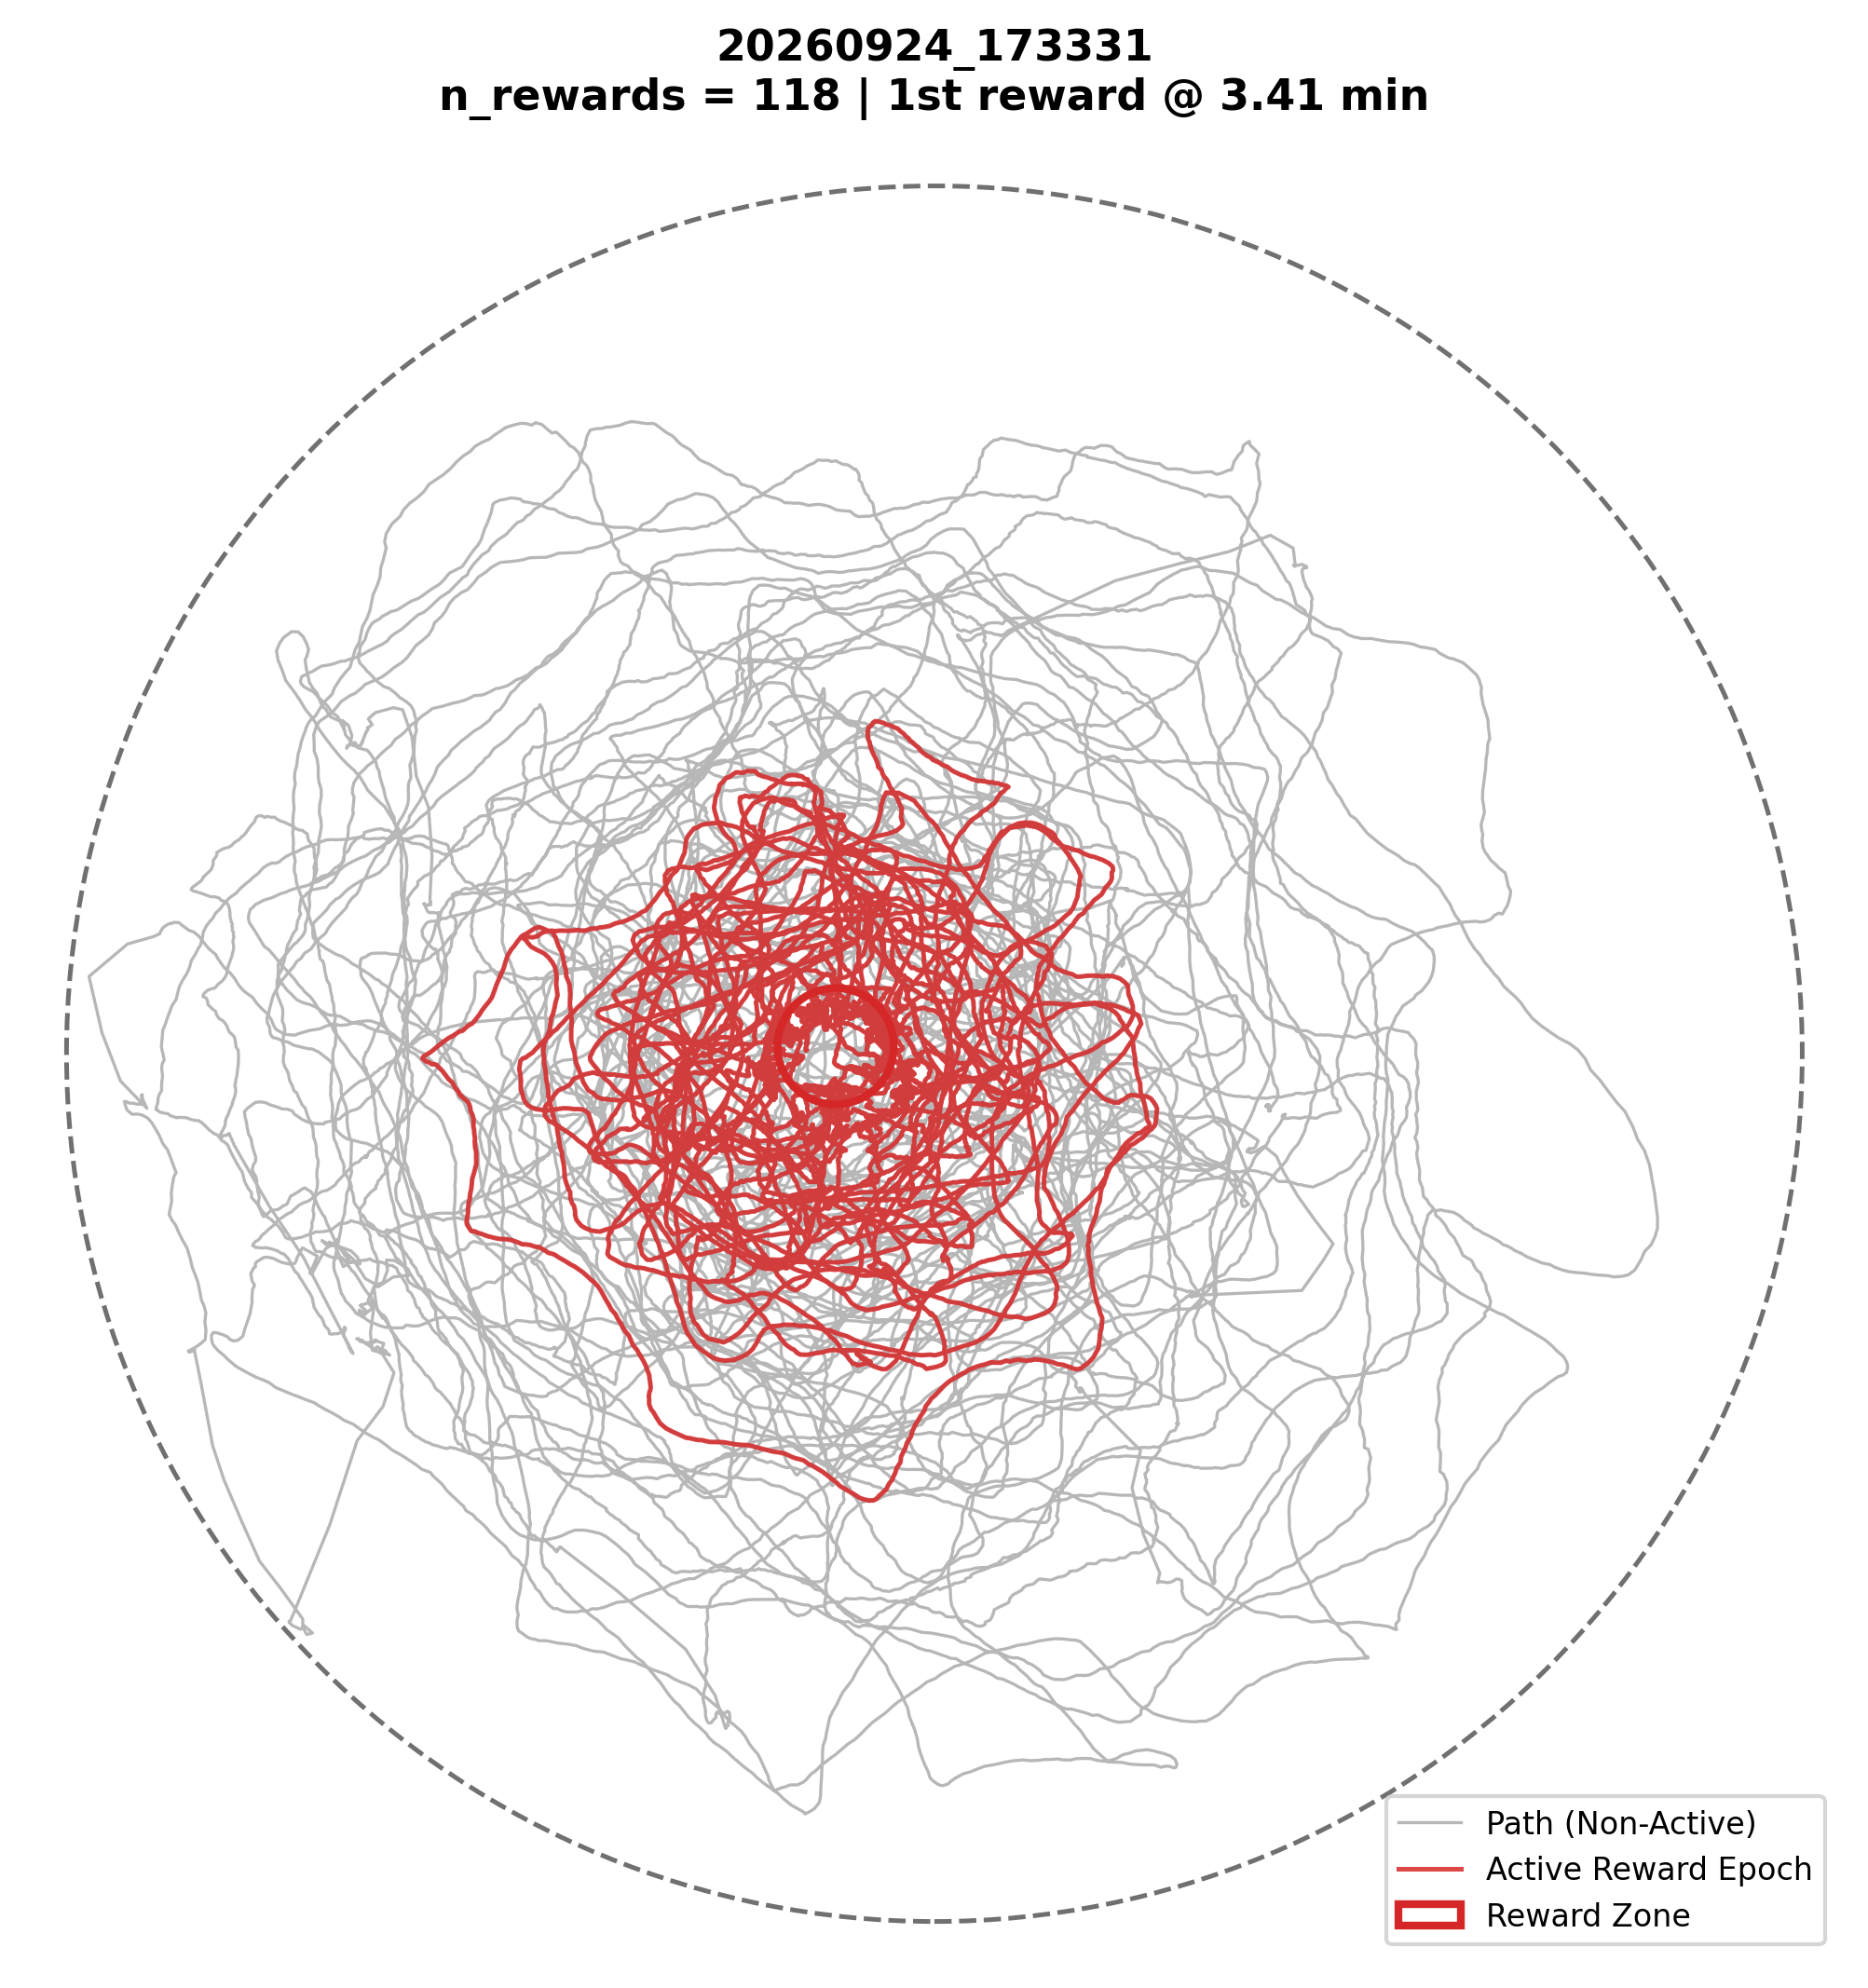

In [7]:
exp = atr_dataset[3]  # Pick first fly

fig, ax = plot_single_fly_trajectory(exp, arena_r=45.0, fps=60.0)
plt.show()

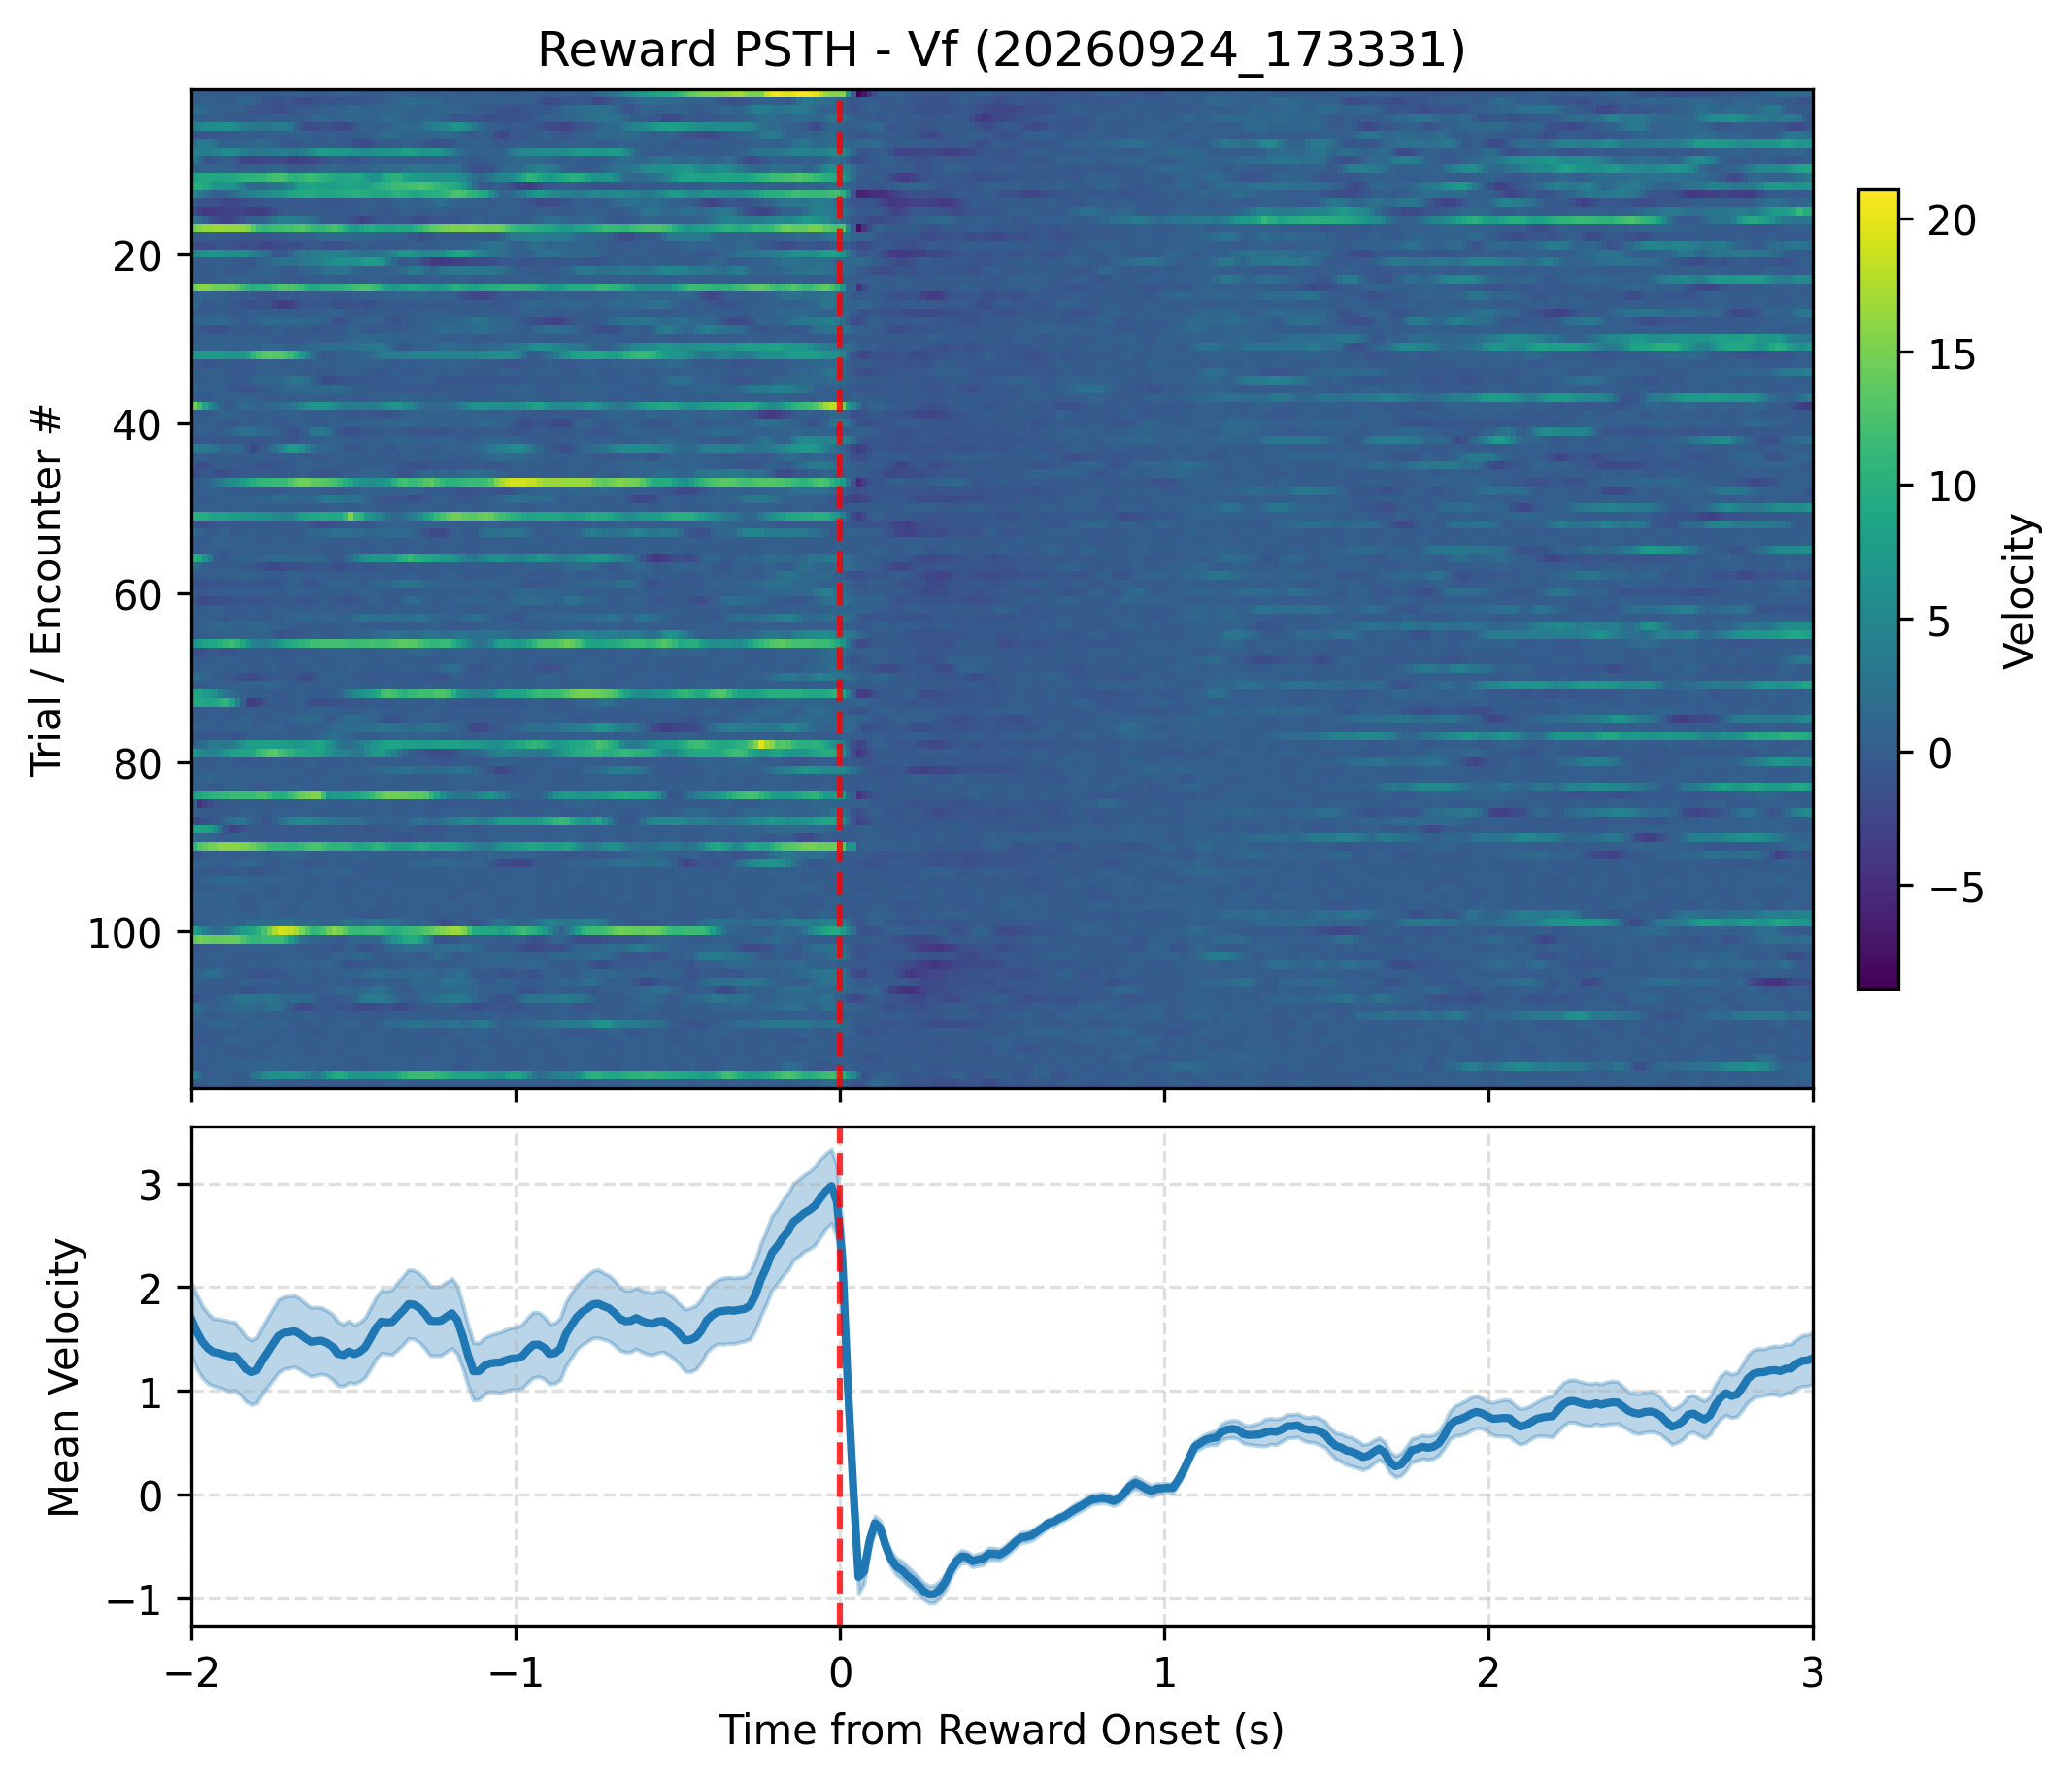

In [8]:
# Extract reward-centered windows (-2s to +4s)
psth_dict = extract_experiment_psth(
    exp, metrics=["Vf_smooth", "Vr_abs"], window_sec=(-2.0, 3.0)
)

# Plot Trial Heatmap + Average Speed Response
fig, axes = plot_single_experiment_psth(
    psth_dict, metric="Vf_smooth", title=exp["uid"]
)
plt.show()

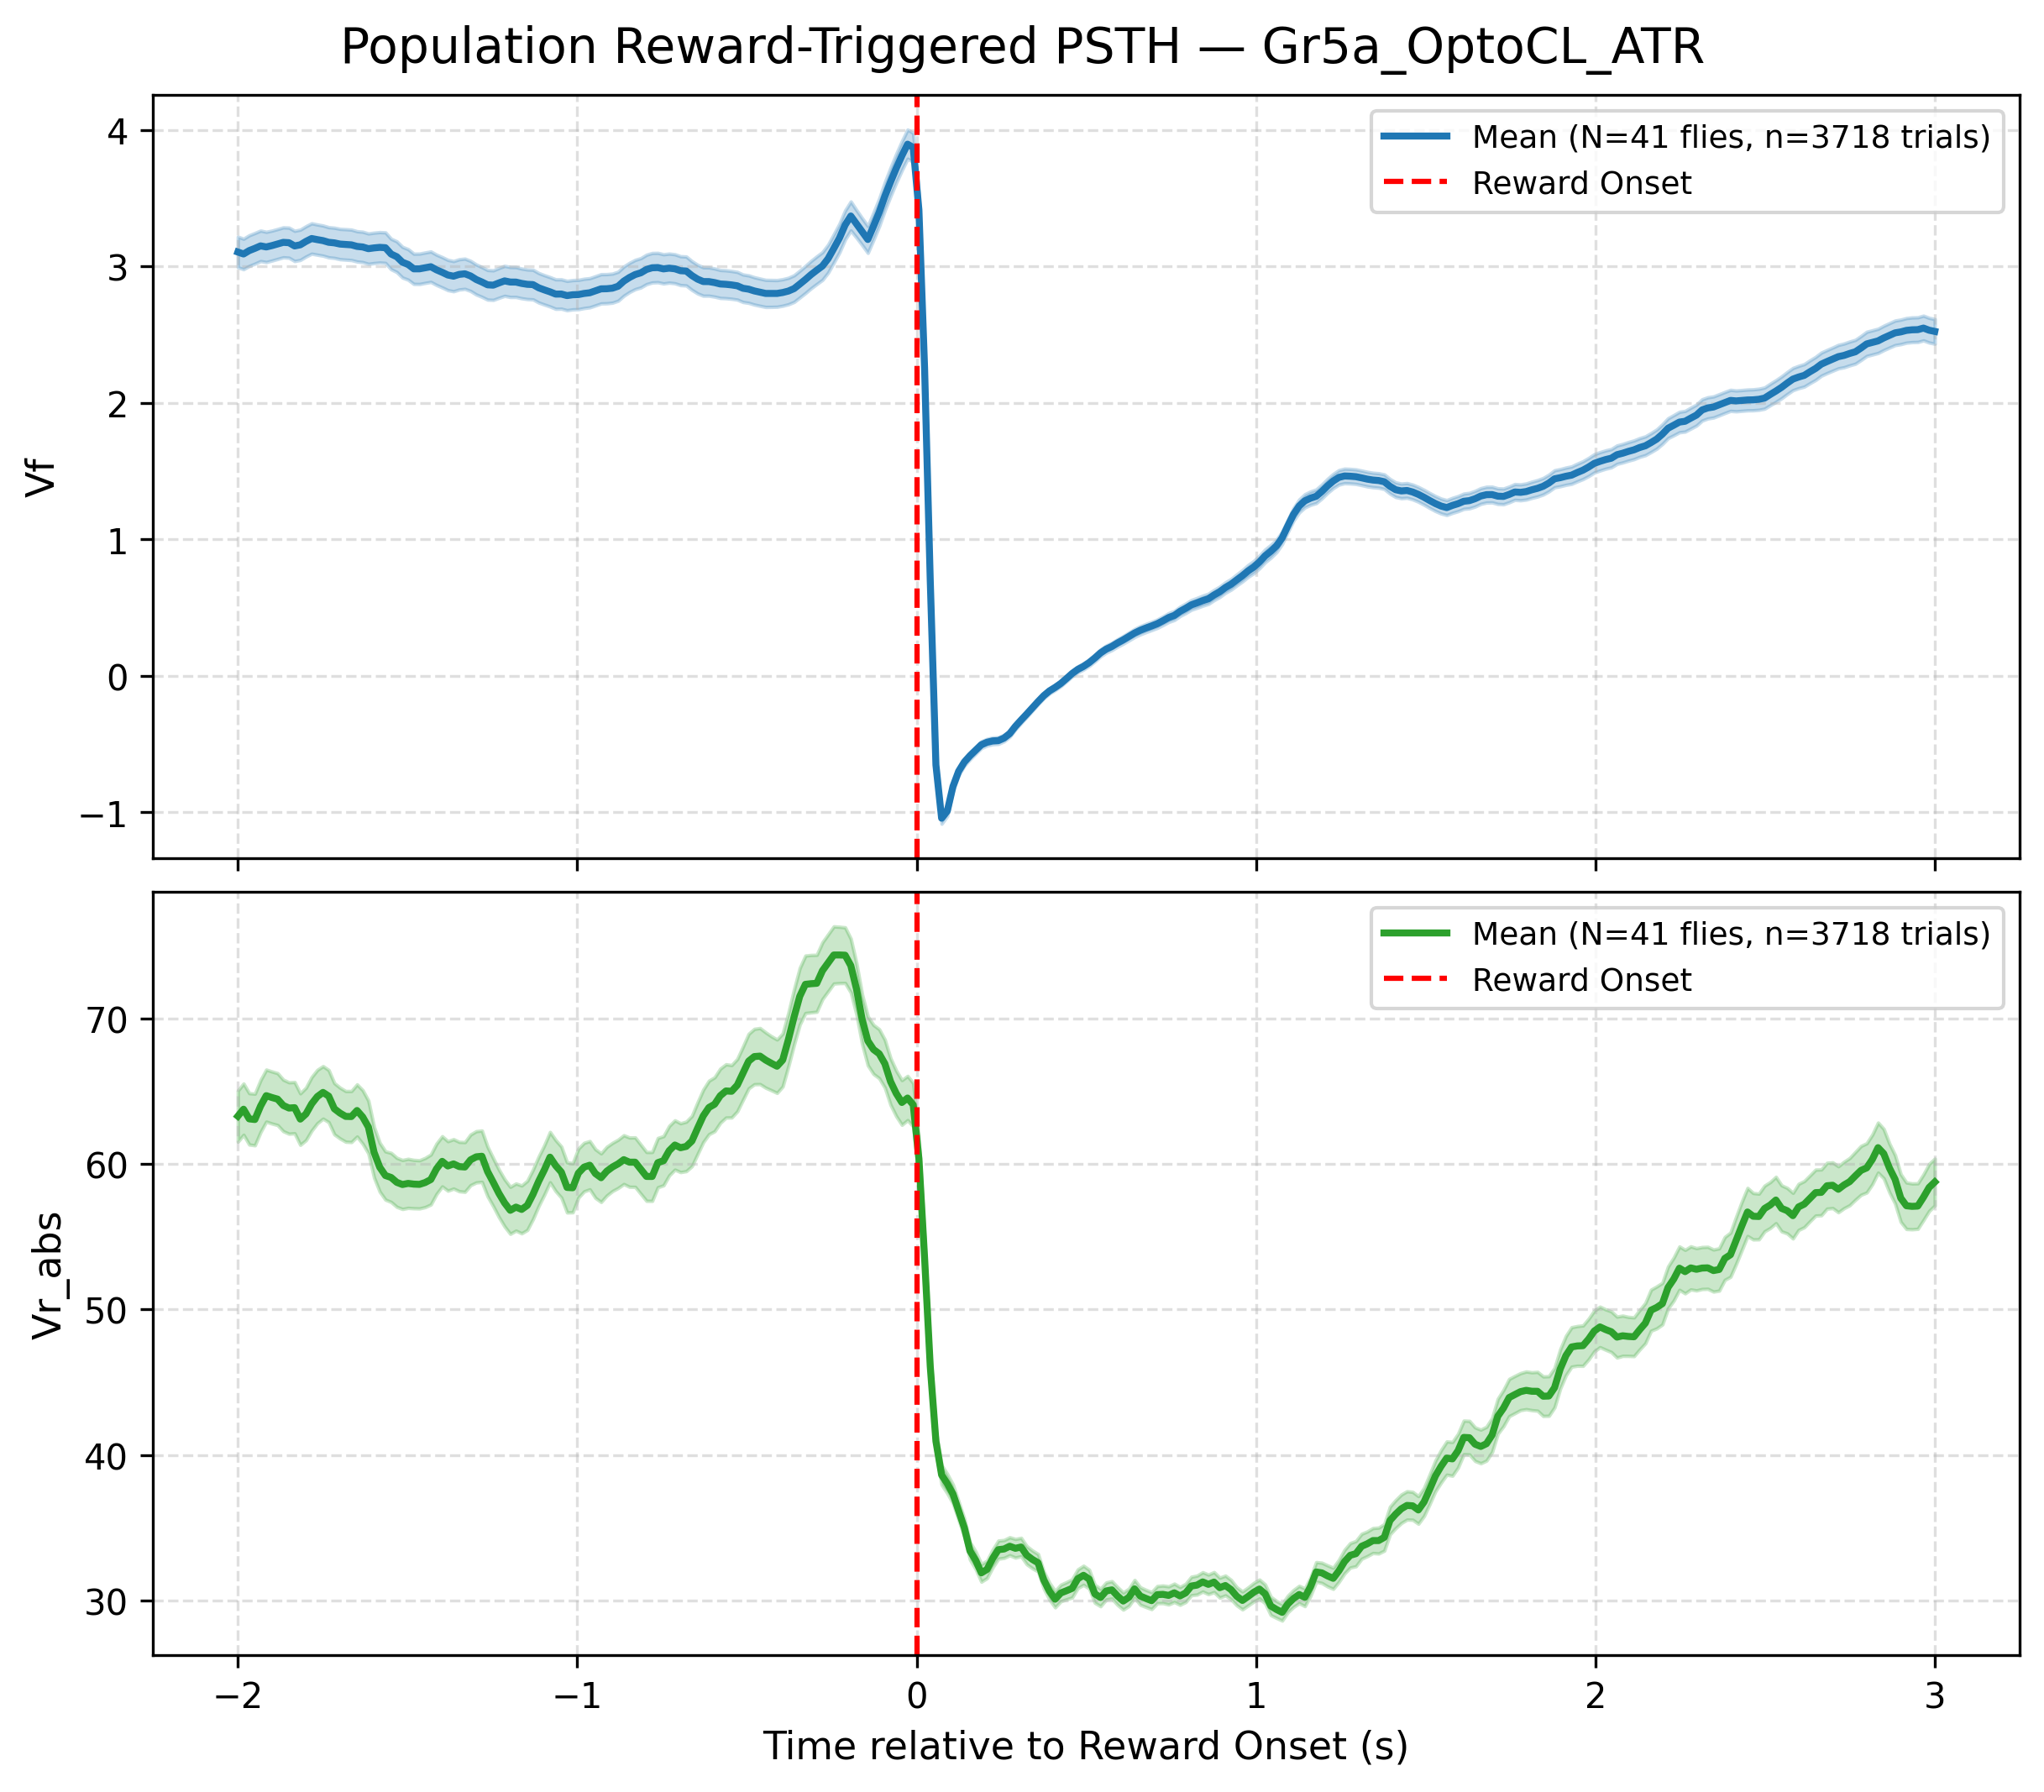

In [9]:
fig, axes = plot_condition_psth_summary(
    atr_dataset,
    condition_name=condition_type,
    metrics=["Vf_smooth", "Vr_abs"],
    window_sec=(-2.0, 3.0),
)
plt.show()

In [14]:
genotype="Gr43a"
protocol="OptoCL"
condition_type = f"{genotype}_{protocol}_{medium}"
df_exp_atr = select_exp_condition(df_metadata, genotype=genotype, protocol=protocol, medium="ATR")
atr_experiments = load_experiment_dataset(df_exp_atr, fps=60.0)
df_exp_nr = select_exp_condition(df_metadata, genotype=genotype, protocol=protocol, medium="NR")
nr_experiments = load_experiment_dataset(df_exp_nr, fps=60.0)

print(f"Loaded {len(atr_dataset)} flies into memory!")
print("Columns in df_track:", atr_experiments[0]["df_track"].columns.tolist())


Loaded 41 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


In [15]:
atr_experiments

[{'file_index': 0,
  'uid': '20260814_165206',
  'folder_path': PosixPath('/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr43a_Gal4/20260814_165206_Gr43a_OptoCL_ATR'),
  'df_track':        Index    X_cal     Y_cal  ori_angle_cal      X_px      Y_px  ori_angle  \
  0          0  74.2561 -139.4239        18.1825  429.9607  337.6832    -0.3173   
  1          1  74.6332 -139.0548        14.5950  429.6218  338.0449    -0.2547   
  2          2  74.5442 -139.2489        19.5851  429.8068  337.9597    -0.3418   
  3          3  74.6882 -139.0039        19.8226  429.5752  338.0976    -0.3460   
  4          4  74.6306 -139.0298        21.7691  429.5970  338.0422    -0.3799   
  ...      ...      ...       ...            ...       ...       ...        ...   
  72408  72408  51.5075  -48.0765      6735.7725  340.6667  316.0972    -1.3225   
  72409  72409  51.6562  -48.3185      6741.3960  340.8998  316.2354    -1.4206   
  72410  72410  51.4767  -48.0893      6737.9820  340.6785  316.0686    -1.

In [16]:
import statsmodels.formula.api as smf
from behavior_fw.utils.iris import extract_enhanced_iri_metrics

# 1. Extract metrics for both groups (skipping the first 1.0 sec transient)
df_atr = extract_enhanced_iri_metrics(
    atr_experiments, group_label="ATR", skip_start_sec=1.0
)
df_nr = extract_enhanced_iri_metrics(
    nr_experiments, group_label="NR", skip_start_sec=1.0
)

# Combine into one master DataFrame
df_all = pd.concat([df_atr, df_nr], ignore_index=True)

# 2. Fit Group Interaction Model: abs_power_asym ~ duration_sec * C(group)
# Tests if the SLOPE over time is significantly different between ATR and NR
model_group_comparison = smf.mixedlm(
    "abs_power_asym ~ duration_sec * C(group)",
    df_all,
    groups=df_all["fly_id"],
)
res_group = model_group_comparison.fit(method="powell")

print("=== ATR vs NR INTERACTION MODEL ===")
print(res_group.summary())

=== ATR vs NR INTERACTION MODEL ===
                 Mixed Linear Model Regression Results
Model:                 MixedLM    Dependent Variable:    abs_power_asym
No. Observations:      2005       Method:                REML          
No. Groups:            49         Scale:                 0.0647        
Min. group size:       1          Log-Likelihood:        -132.2124     
Max. group size:       128        Converged:             Yes           
Mean group size:       40.9                                            
-----------------------------------------------------------------------
                            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    0.629    0.013  46.935 0.000  0.603  0.655
C(group)[T.NR]               0.075    0.041   1.812 0.070 -0.006  0.156
duration_sec                -0.024    0.002 -13.775 0.000 -0.028 -0.021
duration_sec:C(group)[T.NR] -0.001    0.006  

/home/athira/anaconda3/envs/behave/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/tmp/ipykernel_46997/1155962504.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


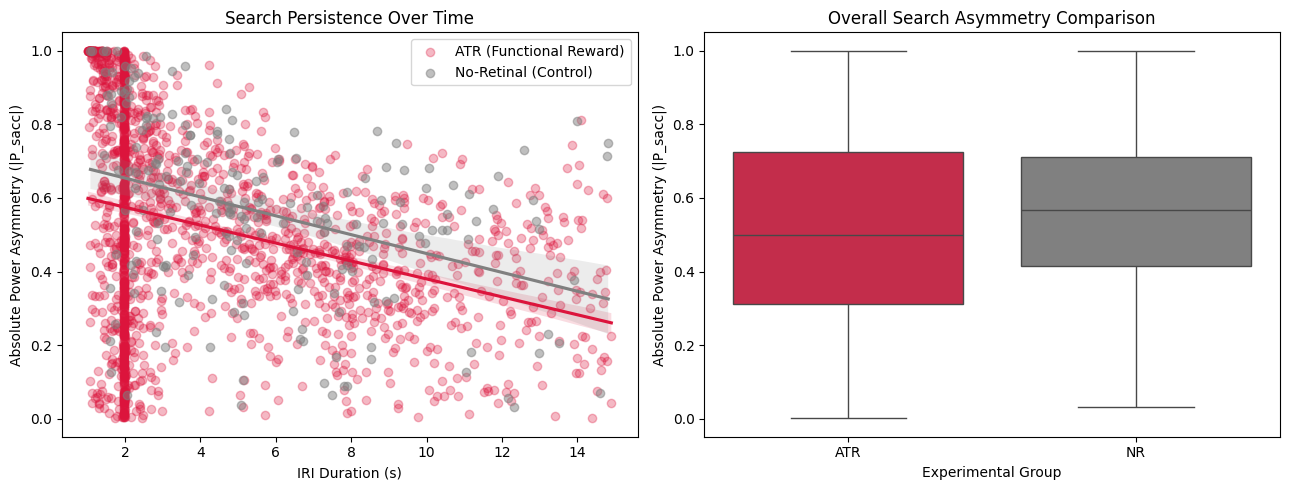

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_atr_vs_nr_comparison(df_all: pd.DataFrame):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Panel 1: Saccadic Power Asymmetry over Duration
    sns.regplot(
        data=df_all[df_all["group"] == "ATR"],
        x="duration_sec",
        y="abs_power_asym",
        ax=axes[0],
        color="crimson",
        label="ATR (Functional Reward)",
        scatter_kws={"alpha": 0.3},
    )

    sns.regplot(
        data=df_all[df_all["group"] == "NR"],
        x="duration_sec",
        y="abs_power_asym",
        ax=axes[0],
        color="gray",
        label="No-Retinal (Control)",
        scatter_kws={"alpha": 0.5},
    )

    axes[0].set_ylabel("Absolute Power Asymmetry (|P_sacc|)")
    axes[0].set_xlabel("IRI Duration (s)")
    axes[0].set_title("Search Persistence Over Time")
    axes[0].legend()

    # Panel 2: Distribution of Asymmetry Scores (Boxplot)
    sns.boxplot(
        data=df_all, x="group", y="abs_power_asym", ax=axes[1], palette=["crimson", "gray"]
    )
    axes[1].set_ylabel("Absolute Power Asymmetry (|P_sacc|)")
    axes[1].set_xlabel("Experimental Group")
    axes[1].set_title("Overall Search Asymmetry Comparison")

    plt.tight_layout()
    plt.show()


# Run plot
plot_atr_vs_nr_comparison(df_all)

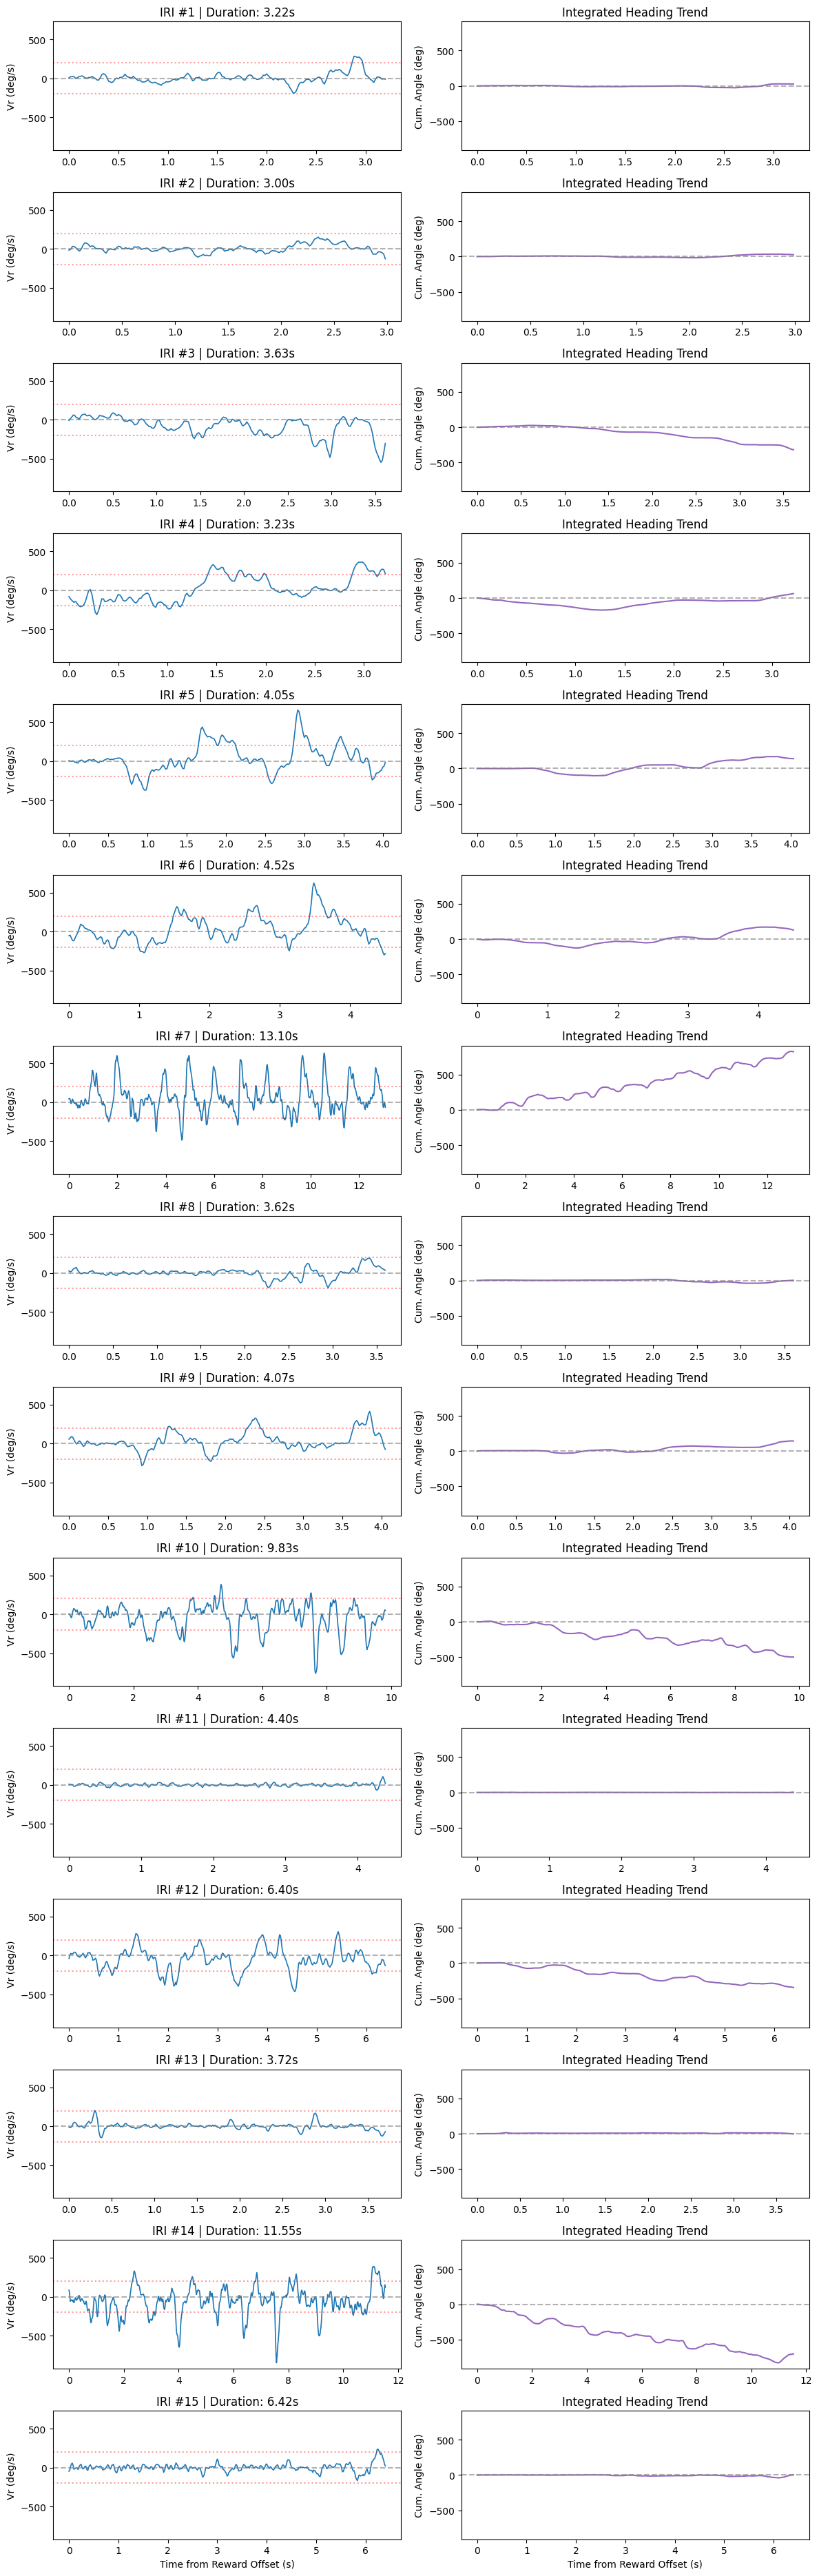

In [20]:
from behavior_fw.utils.iris import extract_iri_rotational_velocity
from behavior_fw.visualization.plot_iri import plot_iri_rotational_velocity, plot_random_iri_samples

# # 1. Extract data
iris = extract_iri_rotational_velocity(exp, min_iri_sec=3, fps=60.0)

# 2. Plot results
plot_iri_rotational_velocity(iris, max_plots=15)

In [ ]:
# from behavior_fw.analysis.detect_turns import detect_iri_saccades, detect_iri_saccade_magnitudes

# # 1. Extract variable-length IRIs from continuous track data
# iris = extract_iri_rotational_velocity(exp, min_iri_sec=3, fps=60.0)

# # 2. Detect saccades and extract saccade_directions for each IRI
# iris = detect_iri_saccades(iris, velocity_threshold=300.0, fps=60.0)

# # # 3. Inspect a random sample of 5 IRIs visually
# # plot_random_iri_samples(iris, n_samples=5, seed=42)



In [ ]:
def test_amplitude_bias_permutation(left_amps: np.ndarray, right_amps: np.ndarray, n_permutations: int = 2000):
    """Permutation test comparing observed net displacement against random sign assignments."""
    all_amps = np.concatenate([left_amps, right_amps])
    N = len(all_amps)
    if N < 2:
        return None

    # Observed net displacement from saccades
    obs_net_disp = np.sum(left_amps) - np.sum(right_amps)

    null_net_disps = []
    for _ in range(n_permutations):
        # Randomly assign +1 or -1 direction to each magnitude
        random_signs = np.random.choice([1, -1], size=N)
        null_disp = np.sum(random_signs * all_amps)
        null_net_disps.append(null_disp)

    null_net_disps = np.array(null_net_disps)
    p_val = np.mean(np.abs(null_net_disps) >= np.abs(obs_net_disp))

    return {
        "obs_net_disp": obs_net_disp,
        "p_value": p_val
    }

In [ ]:


def plot_saccade_amplitude_comparison(iri_data: list):
    all_left_amps = np.concatenate([iri["left_amplitudes"] for iri in iri_data if len(iri["left_amplitudes"]) > 0])
    all_right_amps = np.concatenate([iri["right_amplitudes"] for iri in iri_data if len(iri["right_amplitudes"]) > 0])

    plt.figure(figsize=(7, 4))
    sns.kdeplot(all_left_amps, color="tab:blue", label=f"Left Saccades (n={len(all_left_amps)})", fill=True, alpha=0.3)
    sns.kdeplot(all_right_amps, color="tab:orange", label=f"Right Saccades (n={len(all_right_amps)})", fill=True, alpha=0.3)
    
    plt.xlabel("Saccade Amplitude (degrees)")
    plt.ylabel("Density")
    plt.title("Distribution of Saccade Magnitudes across IRIs")
    plt.legend()
    plt.show()

Extracted 38 valid Inter-Reward Intervals.


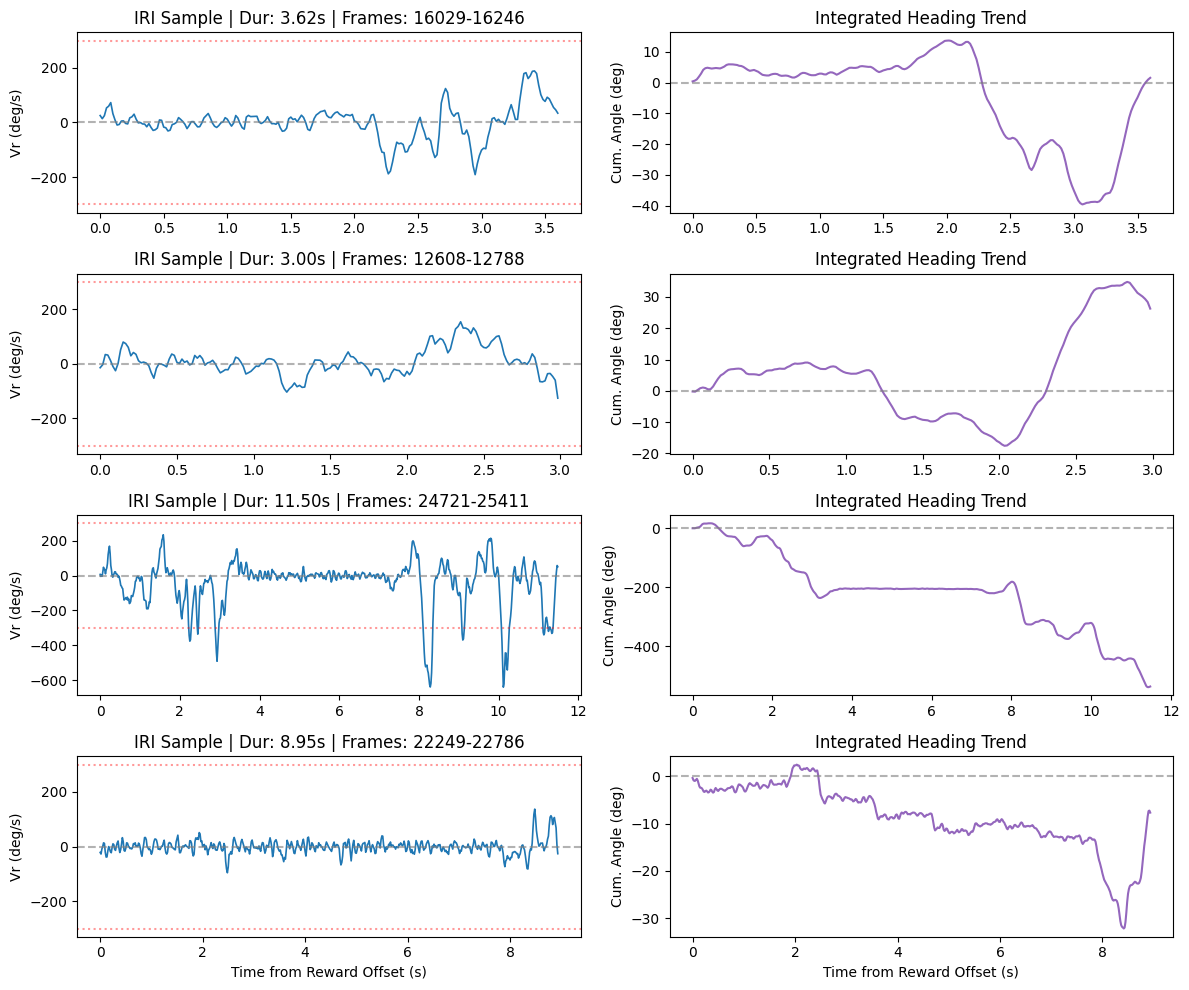

NameError: name 'plot_saccade_amplitude_comparison' is not defined

In [21]:
# 1. Load or prepare your experiment dictionary (containing 'df_track')
# exp = {"df_track": your_pandas_dataframe, "folder_path": "path/to/exp"}

# 2. Extract variable-length IRIs (Reward Offset -> Next Reward Onset)
iris = extract_iri_rotational_velocity(exp, min_iri_sec=3.0, fps=60.0)
print(f"Extracted {len(iris)} valid Inter-Reward Intervals.")

# # 3. Detect saccades & compute amplitude magnitudes per IRI
# iris = detect_iri_saccade_magnitudes(iris, velocity_threshold=300.0, min_distance_sec=0.2, fps=60.0)

# 4. Visually inspect a random sample of 4 IRIs
plot_random_iri_samples(iris, n_samples=4, seed=42)

# 5. Compare the amplitude distributions visually (Left vs Right)
plot_saccade_amplitude_comparison(iris)

# 6. Run Statistical Permutation Tests for Amplitude Bias across all IRIs
all_left_amps = np.concatenate([iri["left_amplitudes"] for iri in iris if len(iri["left_amplitudes"]) > 0])
all_right_amps = np.concatenate([iri["right_amplitudes"] for iri in iris if len(iri["right_amplitudes"]) > 0])

results = test_amplitude_bias_permutation(all_left_amps, all_right_amps, n_permutations=2000)

print(f"Observed Net Saccade Displacement: {results['obs_net_disp']:.2f}°")
print(f"Permutation Test p-value         : {results['p_value']:.4f}")

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import skew


def extract_spike_dominance_metrics(exp_list: list, fps: float = 60.0) -> pd.DataFrame:
    records = []

    for exp_idx, exp in enumerate(exp_list):
        fly_id = exp.get("fly_id", exp.get("folder_path", f"fly_{exp_idx+1}"))
        df_track = exp.get("df_track", None)

        if df_track is None or "LEDstate" not in df_track.columns or "Vr_smooth" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)

        onsets = np.where(led_diff == 1)[0]
        offsets = np.where(led_diff == -1)[0]

        for iri_idx, off_idx in enumerate(offsets):
            next_onsets = onsets[onsets > off_idx]
            if len(next_onsets) == 0:
                continue

            next_on_idx = next_onsets[0]
            dur = (next_on_idx - off_idx) / fps

            if dur < 1.0 or dur > 15.0:
                continue

            vr = df_track["Vr_smooth"].iloc[off_idx:next_on_idx].values

            # 1. Peak Velocity Extremes
            max_pos_peak = np.max(vr) if len(vr) > 0 else 0
            max_neg_peak = np.abs(np.min(vr)) if len(vr) > 0 else 0

            # 2. Peak Asymmetry Ratio [-1, 1]
            denom_peaks = max_pos_peak + max_neg_peak
            peak_asymmetry = (max_pos_peak - max_neg_peak) / denom_peaks if denom_peaks > 0 else 0.0

            # 3. Distribution Skewness (Captures tail asymmetry)
            vr_skewness = skew(vr) if len(vr) > 2 else 0.0

            # 4. Saccadic Power Asymmetry (V^2 ratio)
            pos_power = np.sum(vr[vr > 0] ** 2)
            neg_power = np.sum(vr[vr < 0] ** 2)
            total_power = pos_power + neg_power
            power_asymmetry = (pos_power - neg_power) / total_power if total_power > 0 else 0.0

            # 5. Absolute Dominance Scores (Magnitude regardless of Left/Right)
            abs_peak_asym = abs(peak_asymmetry)
            abs_skewness = abs(vr_skewness)
            abs_power_asym = abs(power_asymmetry)

            records.append({
                "fly_id": fly_id,
                "iri_index": iri_idx,
                "duration_sec": dur,
                "max_pos_peak": max_pos_peak,
                "max_neg_peak": max_neg_peak,
                "peak_asymmetry": peak_asymmetry,
                "abs_peak_asym": abs_peak_asym,
                "vr_skewness": vr_skewness,
                "abs_skewness": abs_skewness,
                "power_asymmetry": power_asymmetry,
                "abs_power_asym": abs_power_asym
            })

    return pd.DataFrame(records)

In [ ]:
import statsmodels.formula.api as smf

# 1. Extract spike-focused dataset
df_spikes = extract_spike_dominance_metrics(dataset)

# 2. Test Saccadic Power Asymmetry
model_power = smf.mixedlm("abs_power_asym ~ duration_sec", df_spikes, groups=df_spikes["fly_id"])
res_power = model_power.fit()

print("--- SACCADIC POWER ASYMMETRY RESULTS ---")
print(res_power.summary())

# 3. Test Velocity Skewness
model_skew = smf.mixedlm("abs_skewness ~ duration_sec", df_spikes, groups=df_spikes["fly_id"])
res_skew = model_skew.fit()

print("\n--- VELOCITY SKEWNESS RESULTS ---")
print(res_skew.summary())